# Road Collision Risk & Spatial Inequality — Week 1 Data Audit

## tl;dr

Keys and parent-child relationships are consistent across the confirmed DfT STATS19 2021–2025 release, and the standalone 2025 file exactly matches the 2025 subset of the combined five-year file. However, coded missing values, the 2024 schema transition, and injury-based severity reporting mean that neither simple missingness rates nor raw severity trends should be interpreted at face value.

## Context & Methods

### Key Assumptions

- The study population is personal-injury collisions on public roads that were reported to the police.
- Collision counts are not risk rates without a traffic-exposure denominator.
- This notebook audits data quality and does not make causal claims.
- Source: https://www.gov.uk/government/statistical-data-sets/road-safety-open-data

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROCESSED = ROOT / 'data' / 'processed'
plt.rcParams.update({'figure.figsize': (9, 4.8), 'axes.grid': True, 'grid.alpha': 0.22, 'font.size': 10})

## Data

### 1. Load reviewed audit outputs

In [2]:
audit_run = subprocess.run([sys.executable, str(ROOT / 'src' / 'audit_stats19.py')], check=True, capture_output=True, text=True)
print('Raw-file audit rerun: OK')
audit = json.loads((PROCESSED / 'audit_summary.json').read_text(encoding='utf-8'))
table_profile = pd.read_csv(PROCESSED / 'table_profile.csv')
annual = pd.read_csv(PROCESSED / 'annual_collision_quality.csv')
coded_missing = pd.read_csv(PROCESSED / 'coded_missingness.csv')
table_profile

Raw-file audit rerun: OK


,table,rows,columns,candidate_key,duplicate_full_rows,duplicate_key_rows,null_key_rows
0,collision,101525,44,collision_index,0,0,0
1,vehicle,183948,32,collision_index+vehicle_reference,0,0,0
2,casualty,127883,24,collision_index+casualty_reference,0,0,0


## Results

### 2. Check keys and relationships

In [3]:
integrity = pd.Series(audit['integrity'], name='rows')
assert table_profile['duplicate_key_rows'].sum() == 0
assert table_profile['null_key_rows'].sum() == 0
assert integrity.sum() == 0
integrity.to_frame()

,rows
vehicle_rows_without_collision,0
casualty_rows_without_collision,0
casualty_rows_without_matching_vehicle_reference,0


### 3. Review five-year coverage and severity composition

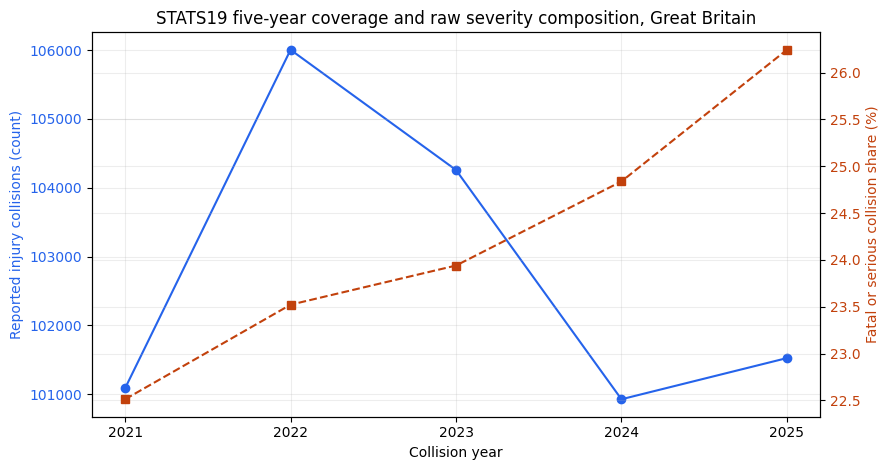

,collision_year,collisions,serious_or_fatal,missing_coordinates,serious_or_fatal_share
0,2021,101087,22758,17,22.5%
1,2022,106004,24935,22,23.5%
2,2023,104258,24960,12,23.9%
3,2024,100927,25069,0,24.8%
4,2025,101525,26644,2,26.2%


In [4]:
fig, ax1 = plt.subplots()
ax1.plot(annual['collision_year'], annual['collisions'], marker='o', color='#2563EB', label='Reported injury collisions')
ax1.set_xlabel('Collision year')
ax1.set_ylabel('Reported injury collisions (count)', color='#2563EB')
ax1.tick_params(axis='y', labelcolor='#2563EB')
ax1.set_xticks(annual['collision_year'])
ax2 = ax1.twinx()
ax2.plot(annual['collision_year'], annual['serious_or_fatal_share'] * 100, marker='s', linestyle='--', color='#C2410C', label='Fatal/serious collision share')
ax2.set_ylabel('Fatal or serious collision share (%)', color='#C2410C')
ax2.tick_params(axis='y', labelcolor='#C2410C')
ax1.set_title('STATS19 five-year coverage and raw severity composition, Great Britain')
fig.tight_layout()
plt.show()
annual.style.format({'serious_or_fatal_share': '{:.1%}'})

The raw fatal-or-serious collision share rose from 22.5% in 2021 to 26.2% in 2025. This should not be interpreted directly as an increase in underlying risk because injury-based reporting and adjusted-severity guidance affect comparability.

### 4. Inspect coded missingness

In [5]:
(coded_missing[['table', 'column', 'unknown_codes', 'coded_missing_pct']]
 .sort_values('coded_missing_pct', ascending=False)
 .head(15)
 .style.format({'coded_missing_pct': '{:.1f}%'}))

,table,column,unknown_codes,coded_missing_pct
0,vehicle,journey_purpose_of_driver_historic,-1|15|6,71.0%
1,vehicle,journey_purpose_of_driver,-1|6,66.8%
2,casualty,casualty_distance_banding,-1,65.7%
3,collision,junction_control,-1|9,44.6%
4,vehicle,vehicle_manoeuvre_historic,-1|99,36.4%
5,vehicle,vehicle_location_restricted_lane_historic,-1|99,35.9%
6,casualty,enhanced_casualty_severity,-1,34.7%
7,collision,second_road_number,-1,34.7%
8,collision,pedestrian_crossing_human_control_historic,-1|9,32.9%
9,collision,pedestrian_crossing_physical_facilities_historic,-1|9,32.3%


## Takeaways

- Keys, relationships, and release consistency are sufficiently stable for downstream modelling.
- Missingness must be interpreted with field-specific codebooks; a global replacement of `-1`, `9`, or `99` is not valid.
- Raw and adjusted severity should be preserved in parallel, with sensitivity analysis by year and police force.
- Spatial risk rates should only be calculated after confirming the applicable grain of AADF or local-area vehicle-miles exposure.